# 01 – Chuẩn bị dữ liệu (B0 → B5)

Notebook chung của nhóm. Mỗi phần B0…B5 do một người viết (xem `PIPELINE_DO_AN_ML.md`, mục 3).

---
## B0. Định nghĩa bài toán và thang đo *(Người 3)*

### B0.1 Bài toán

| | |
|---|---|
| **Loại bài toán** | Hồi quy có giám sát |
| **Đơn vị quan sát** | Một sản phẩm tai nghe Bluetooth đang bán trên Lazada.vn (một `item_id`) |
| **Thời điểm dự đoán** | Lúc người bán **vừa đăng** sản phẩm. Chỉ dùng thông tin có sẵn lúc đó: tên, thương hiệu, thông số, thông tin shop, % giảm giá |
| **Đầu ra** | Giá bán `price` (VNĐ). Mô hình học **`log10(price)`**, kết quả báo cáo đổi lại về VNĐ |
| **Ứng dụng** | (1) Người bán mới nhập thông tin sản phẩm → nhận giá gợi ý. (2) Người mua phát hiện sản phẩm bị định giá quá cao so với sản phẩm tương tự |

**Hệ quả của "thời điểm dự đoán":** mọi cột chỉ có sau khi sản phẩm đã bán một thời gian (lượt bán, số đánh giá, điểm sao, tỉ lệ mua lại, thứ hạng tìm kiếm) và cột chứa sẵn đáp án (`original_price`: giá gốc × (1 − % giảm) = giá) đều là **rò rỉ dữ liệu** và bị loại. Danh sách nằm ở `chung.COT_RO_RI`; Người 2 kiểm tra lại ở B2.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import chung

pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
raw = pd.read_csv('../data/raw/lazada_tai_nghe_1500.csv')
print(raw.shape)
print('Cột rò rỉ có trong dữ liệu:', [c for c in chung.COT_RO_RI if c in raw.columns])

(1550, 73)
Cột rò rỉ có trong dữ liệu: ['price', 'original_price', 'discount_raw', 'rating_score', 'review_count', 'sold_raw', 'sold_num', 'rating_avg_detail', 'rating_count_detail', 'star_1', 'star_2', 'star_3', 'star_4', 'star_5', 'repurchase_rate', 'returning_customers', 'reviews_with_media', 'review_tag_repurchase', 'review_tags_raw', 'search_page', 'rank_in_page']


### B0.2 Biến mục tiêu: vì sao dùng `log10(price)`

Lọc **tạm** theo khoảng giá 30.000 – 20.000.000 đ để xem phân phối (luật làm sạch chính thức ở B1, dùng đúng hàm `chung.lam_sach`).

In [2]:
df, _ = chung.lam_sach(raw)
print(f'Sau làm sạch tạm: {len(df)} dòng')

tom_tat = pd.DataFrame({
    'price (VNĐ)': df['price'].describe(),
    'log10(price)': df[chung.TARGET].describe(),
}).T
tom_tat['skew'] = [df['price'].skew(), df[chung.TARGET].skew()]
tom_tat

Sau làm sạch tạm: 1539 dòng


,count,mean,std,min,25%,50%,75%,max,skew
price (VNĐ),"1,539.000","433,113.462","796,966.347","30,000.000","131,058.000","224,000.000","457,000.000","14,990,000.000",8.241
log10(price),"1,539.000",5.391,0.424,4.477,5.117,5.350,5.660,7.176,0.471


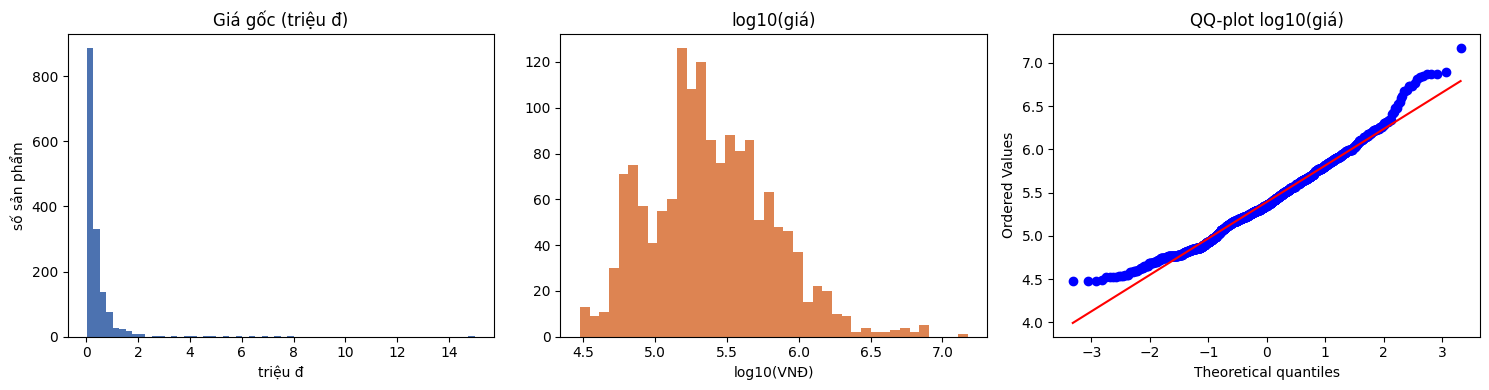

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df['price'] / 1e6, bins=60, color='#4C72B0')
ax[0].set(title='Giá gốc (triệu đ)', xlabel='triệu đ', ylabel='số sản phẩm')
ax[1].hist(df[chung.TARGET], bins=40, color='#DD8452')
ax[1].set(title='log10(giá)', xlabel='log10(VNĐ)')
stats.probplot(df[chung.TARGET], dist='norm', plot=ax[2])
ax[2].set_title('QQ-plot log10(giá)')
plt.tight_layout(); plt.show()

**Nhận xét:**
- Giá gốc lệch phải rất mạnh (skew ở bảng trên): đa số dưới 500 nghìn nhưng đuôi kéo tới hàng chục triệu. Nếu học trên giá gốc, MSE bị vài sản phẩm đắt chi phối; sai 100k với tai nghe 150k (67%) bị xem nhẹ hơn sai 200k với tai nghe 5 triệu (4%).
- Sau `log10`, phân phối gần đối xứng (skew xấp xỉ 0,5), QQ-plot gần thẳng. Sai số trên log là **sai số tương đối**, đều giữa hàng rẻ và hàng đắt, đúng với cách người mua nhìn giá.
- Chọn **log10** thay vì ln để dễ đọc: 5 = 100 nghìn, 6 = 1 triệu. So sánh định lượng log vs giá gốc (KB-C-07) chạy sau khi có `abt_gia.csv`.

### B0.3 Thang đo

| Thang đo | Vai trò | Hàm trong `chung.py` | Cách đọc |
|---|---|---|---|
| **RMSE trên log10(giá)** | **Chính**: chọn mô hình, tinh chỉnh (`scoring="neg_root_mean_squared_error"`) | `rmse_log` | Nhỏ hơn tốt hơn. `10**RMSE` = giá dự đoán thường lệch bao nhiêu lần |
| R² (trên log) | Phụ | `r2_log` | Tỉ lệ biến thiên của log giá được giải thích |
| MAE (VNĐ) | Phụ, dễ hiểu với người bán | `mae_vnd` | Lệch trung bình bao nhiêu đồng (bị hàng đắt kéo lên) |
| MAPE (%) | Phụ | `mape` | Lệch trung bình bao nhiêu % |
| % trúng ±20% | Phụ, gắn với ứng dụng | `ty_le_trung_20` | Bao nhiêu % sản phẩm có giá gợi ý lệch dưới 20% |

`chung.tinh_thang_do(y_true_log, y_pred_log)` trả cả 5 thang đo với tên khóa thống nhất; `danh_gia_cv` ở B5 sẽ gọi hàm này.

**Vì sao RMSE log là thang đo chính:** khớp với hàm mất mát của hầu hết mô hình (bình phương sai số), không bị hàng đắt chi phối như MAE VNĐ, và phạt nặng các lần đoán lệch xa (quan trọng vì giá gợi ý lệch gấp đôi là không dùng được).

In [4]:
# Diễn giải RMSE log10 thành "lệch bao nhiêu lần"
pd.DataFrame({'rmse_log': [0.439, 0.380, 0.343, 0.307, 0.282, 0.266]},
             index=['Dummy (trung vị)', 'Trung vị theo thương hiệu', 'Linear', 'Ridge + TF-IDF (mốc B6)', 'mục tiêu R² 0,55 (≈ 0,42·√0,45)', 'rất tốt R² 0,60']
            ).assign(lech_x_lan=lambda d: d['rmse_log'].map(chung.he_so_sai))

,rmse_log,lech_x_lan
Dummy (trung vị),0.439,2.748
Trung vị theo thương hiệu,0.380,2.399
Linear,0.343,2.203
Ridge + TF-IDF (mốc B6),0.307,2.028
"mục tiêu R² 0,55 (≈ 0,42·√0,45)",0.282,1.914
"rất tốt R² 0,60",0.266,1.845


In [5]:
# Kiểm tra nhanh các hàm thang đo (KHÔNG phải baseline chính thức, baseline làm ở B5 với CV)
y = df[chung.TARGET].to_numpy()
du_doan_trung_vi = np.full_like(y, np.median(y))
du_doan_hoan_hao = y.copy()
du_doan_gap_doi = y + np.log10(2)   # đoán mọi giá gấp đôi
pd.DataFrame({'trung vị toàn bộ': chung.tinh_thang_do(y, du_doan_trung_vi),
              'hoàn hảo': chung.tinh_thang_do(y, du_doan_hoan_hao),
              'luôn gấp đôi': chung.tinh_thang_do(y, du_doan_gap_doi)}).T

,rmse_log,r2,mae_vnd,mape_pct,trung_20_pct
trung vị toàn bộ,0.426,-0.009,"306,429.610",87.438,17.024
hoàn hảo,0.000,1.000,0.000,0.000,100.000
luôn gấp đôi,0.301,0.496,"433,113.462",100.000,0.000


Hàm chạy đúng như kỳ vọng: dự đoán hoàn hảo cho RMSE 0, R² 1, trúng 100%; đoán gấp đôi cho RMSE log = log10(2) ≈ 0,301, MAPE 100%.

### B0.4 Mục tiêu đặt trước và quy tắc chọn mô hình

- **Giao thức chấm:** CV `GroupKFold(5)` theo shop trên 80% train (cột `fold` do Người 2 tạo ở B4). Luôn báo cáo kèm điểm KFold ngẫu nhiên để thấy mức "đẹp giả".
- **Mốc phải thắng** (KB-C-03, thử nhanh 26/11): RMSE log < **0,307** (Ridge + TF-IDF tên, R² 0,49).
- **Mục tiêu:** R² ≥ **0,55** theo GroupKFold là "tốt", ≥ 0,60 là "rất tốt". Không đặt 0,70: lần thử trước đạt 0,58 là do chia ngẫu nhiên (cùng shop ở cả train và test); chia theo shop thì Linear chỉ đạt 0,36.
- **Quy tắc chọn:** mô hình có RMSE log CV trung bình thấp nhất. Nếu chênh lệch nhỏ hơn độ lệch chuẩn qua fold (hoặc t-test ghép cặp ở B7 có p ≥ 0,05) thì coi là ngang nhau và chọn mô hình **đơn giản / nhanh hơn**.
- **Tập test** chỉ mở một lần ở B7.
- ⭐ Bài toán phụ phân loại phân khúc giá (rẻ / trung / cao): chỉ làm nếu thầy yêu cầu.

---
## B1. Làm sạch dữ liệu *(Người 1)*

- **Nguồn:** tự cào Lazada.vn (13/11 và 19/11/2026), 5 từ khóa tìm kiếm. Bộ chính thức `data/raw/lazada_tai_nghe_1500.csv`.
- **Luật** nằm trong `chung.lam_sach()` để B3 và demo dùng lại đúng một cách. Các luật chỉ dùng thông tin của chính dòng đó nên làm **trước** khi chia train/test, không gây rò rỉ.
- Cắt ngưỡng ngoại lệ cho các cột thông số (giờ pin, trở kháng…) **không** làm ở đây mà ở B2/B3, sau khi Người 2 chốt bảng cột giữ/bỏ.

In [6]:
raw = pd.read_csv('../' + chung.DUONG_DAN_THO)
sach, nhat_ky = chung.lam_sach(raw)
bang_lam_sach = pd.DataFrame(nhat_ky, columns=['Bước', 'Số dòng bỏ', 'Số dòng còn'])
bang_lam_sach

,Bước,Số dòng bỏ,Số dòng còn
0,0. Dữ liệu thô,0,1550
1,1. Bỏ trùng item_id,0,1550
2,"2. Xóa product_type sai danh mục (35 dòng, giữ...",0,1550
3,"3. Giữ giá 30,000 – 20,000,000 đ",11,1539


### B1.1 Kiểm tra từng luật

In [7]:
# Luật 2: product_type không phải tai nghe, nhưng TÊN cho thấy đều là tai nghe
sai = sach[sach['sai_danh_muc'] == 1]
print(f'{len(sai)} dòng, danh mục gốc:', raw.loc[raw['item_id'].isin(sai['item_id']), 'product_type'].nunique(), 'loại')
raw.loc[raw['item_id'].isin(sai['item_id']), ['name', 'product_type', 'price']].head(12)

35 dòng, danh mục gốc: 23 loại


,name,product_type,price
9,SEA JJT Tai nghe không dây Pro4 TWS với pin lâ...,Phụ kiện thời trang khác,"52,000.000"
34,"Tai Nghe Bluetooth Anker soundcore Liberty 5, ...",Phụ kiện thiết bị âm thanh di động,"2,090,000.000"
56,【FORESIGHT 】Tai Nghe Bluetooth Y10 Cho Mũ Bảo ...,Phụ kiện mũ bảo hiểm,"137,100.000"
68,VINTLOOK Mới không Dây M10 Tai Nghe Bluetooth ...,Phụ kiện tóc nữ,"61,740.000"
74,JINHF Clip-on Tai nghe bluetooth thoải mái mở ...,Micro,"76,377.000"
172,"Tai nghe Bluetooth Pro4 với âm thanh HiFi, thờ...",Phụ kiện treo điện thoại,"50,000.000"
193,STAR FRUIT Pro5s không dây trong tai tai nghe ...,Thắt lưng nữ,"55,100.000"
242,STAR FRUIT Tai nghe bluetooth không dây với tu...,Mật Ong,"55,100.000"
266,Calcenubes Tai nghe bluetooth không dây với mà...,Phụ kiện thời trang khác,"65,000.000"
301,Clemine Tai nghe Bluetooth không dây thiết kế ...,Phụ kiện thời trang khác,"105,000.000"


Ban đầu pipeline định **bỏ** các dòng có danh mục không phải tai nghe. Đọc tên cả 35 dòng thì **tất cả đều là tai nghe Bluetooth thật** (Anker Liberty 5, Bose QuietComfort Ultra, Redmi Buds 6, KZ AN01, tai nghe mũ bảo hiểm FreedConn…), chỉ là shop chọn sai danh mục ("Mật Ong", "Thắt lưng nữ", "Bình nước thể thao"). Bỏ chúng sẽ mất cả những sản phẩm đắt hiếm có. Vì vậy: **giữ dòng**, đặt `product_type` thành trống (để B3 xử lý như "không rõ loại") và thêm cờ `sai_danh_muc`.

Kiểm tra thêm bằng tên: chỉ 2/1.550 tên không chứa "tai nghe / headphone / earbud / tws / buds", và cả 2 cũng là tai nghe (gõ sai "Tai Nge", "Tai đôi"). Các tên có "đệm tai", "cáp sạc", "ốp" đều là tai nghe kèm phụ kiện, không phải phụ kiện bán lẻ.

In [8]:
# Luật 3: các dòng bị loại vì giá (trong số đã là tai nghe)
raw.loc[~raw['price'].between(chung.GIA_MIN, chung.GIA_MAX), ['name', 'price', 'product_type']].sort_values('price')

,name,price,product_type
114,TAI NGHE BLUETOOTH S109 Tai Nghe Không Dây Kết...,"15,000.000",Tai nghe không dây
10,QIUWU Tai Nghe Không Dây Với Microphone Tai Ng...,"17,062.000",NaN
715,Taidu mở Khuyên tai tai nghe bluetooth với tuổ...,"21,000.000",Tai nghe nhét tai
238,Tai Nghe Blutooth 5.0 Đeo Cổ Thể Thao Pin Trâu...,"25,000.000",Tai nghe không dây
105,QIUWU Tai nghe dẫn khí bluetooth không dây âm ...,"26,046.000",Tai nghe hở tai
272,[GIÁ SỐC] Tai Nghe Bluetooth Mini S530 - Không...,"26,900.000",Tai nghe không dây
240,tai nghe bluetooth kèm cáp sạc âm thanh êm hay...,"26,900.000",Tai nghe không dây
550,Tai nghe bluetooth nhét tai Music cao cấp kèm ...,"27,000.000",Tai nghe không dây
45,QIUWU Tai Nghe Không Dây Với Màn Hình Hiển Thị...,"29,538.000",Tai nghe chụp tai cỡ lớn
236,Tai nghe Bluetooth - Tai nghe nhét tai không d...,"29,994.000",Tai nghe không dây


- Dưới 30.000 đ (10 dòng): tai nghe siêu rẻ hoặc giá "mồi" của một phân loại (dây sạc, 1 bên tai), không đại diện cho giá sản phẩm.
- 77,2 triệu đ (Kinera Verdandi): đúng là hàng cao cấp nhưng gấp 5 lần sản phẩm đắt thứ hai; một điểm như vậy làm méo mô hình tuyến tính và không có đủ hàng tương tự để học.
- Ảnh hưởng của ngưỡng được thử lại ở KB-C-08 (30k–20tr vs không lọc vs 50k–10tr).

### B1.2 Dòng thiếu thông tin chi tiết (giữ lại)

In [9]:
print(pd.crosstab(sach['detail_status'], sach['seller_name'].isna(), margins=True)
      .rename(columns={False: 'có tên shop', True: 'thiếu tên shop'}))
print()
print('Tỉ lệ trống của một số cột chi tiết, theo nhóm thiếu_chi_tiết:')
cot = ['seller_name', 'brand', 'bluetooth_version_num', 'battery_hours_num', 'warranty_months', 'positive_seller_rating']
(sach.groupby('thieu_chi_tiet')[cot].apply(lambda g: g.isna().mean() * 100)).round(1)

seller_name    có tên shop  thiếu tên shop   All
detail_status                                   
app_only                 1               2     3
ok                      47               0    47
ok_dom                1339               0  1339
timeout                  1             149   150
All                   1388             151  1539

Tỉ lệ trống của một số cột chi tiết, theo nhóm thiếu_chi_tiết:


,seller_name,brand,bluetooth_version_num,battery_hours_num,warranty_months,positive_seller_rating
thieu_chi_tiet,,,,,,
0,0.000,15.100,23.900,67.700,68.800,1.400
1,98.700,98.700,100.000,100.000,100.000,100.000


- 153 dòng `timeout`/`app_only` chỉ có cột listing (tên, giá, nơi bán, % giảm giá): trống tên shop, loại sản phẩm và mọi thông số. **Giữ lại** vì tên sản phẩm vẫn mang nhiều thông tin giá (KB-C-06), và mô hình triển khai thật cũng sẽ gặp sản phẩm khai thiếu thông số. Cờ `thieu_chi_tiet` được thêm để B2/B3 quyết định có dùng làm đặc trưng không; KB-C-13 thử giữ vs bỏ.
- Dòng thiếu `seller_name` sẽ được gán nhóm riêng `"unknown_" + item_id` ở B4.

### B1.3 Kiểm tra sau làm sạch

In [10]:
print('Trùng item_id:', sach['item_id'].duplicated().sum())
print('Giá trống:', sach['price'].isna().sum(), '| Tên trống:', sach['name'].isna().sum())
print('Khoảng giá:', f"{sach['price'].min():,.0f} – {sach['price'].max():,.0f} đ")
print('Số shop (có tên):', sach['seller_name'].nunique())
print('Theo đợt cào:', sach['crawl_time'].str[:10].value_counts().to_dict())
print('Theo từ khóa:', sach['search_query'].value_counts().to_dict())
tr = sach.duplicated(['name', 'seller_name'], keep=False) & sach['seller_name'].notna()
print(f'Cùng tên + cùng shop (khác item_id): {tr.sum()} dòng → giữ; GroupKFold theo shop giữ chúng cùng một phía nên không rò rỉ')

Trùng item_id: 0
Giá trống: 0 | Tên trống: 0
Khoảng giá: 30,000 – 14,990,000 đ
Số shop (có tên): 326
Theo đợt cào: {'2026-11-19': 1103, '2026-11-13': 436}
Theo từ khóa: {'tai nghe bluetooth': 551, 'tai nghe không dây': 284, 'tai nghe nhét tai bluetooth': 284, 'tai nghe chụp tai bluetooth': 210, 'tai nghe true wireless': 210}
Cùng tên + cùng shop (khác item_id): 15 dòng → giữ; GroupKFold theo shop giữ chúng cùng một phía nên không rò rỉ


In [11]:
sach.to_csv('../' + chung.DUONG_DAN_SACH, index=False, encoding='utf-8-sig')
print('Đã lưu', chung.DUONG_DAN_SACH, sach.shape)

Đã lưu data/lazada_sach.csv (1539, 76)


**Kết quả B1:** xem bảng đầu mục (số dòng sau mỗi bước, đưa thẳng vào báo cáo mục 2). File `data/lazada_sach.csv` là đầu vào của B2 (EDA) và B3 (đặc trưng); file này chưa phải `abt_gia.csv`.